# Allen–Cahn PDE conditioning of a Gaussian process

We fit a Gaussian process (GP) to sparse, early-time observations of a solution to the Allen–Cahn equation

$$u_t = \epsilon\, u_{xx} + 5\,(u - u^3), \qquad x \in [-1, 1],\ t \in [0, 1],$$

and then use guided flow sampling to draw fields from the GP posterior that also approximately satisfy the PDE with periodic boundary conditions. The data only constrain $t < 0.28$; the physics conditions shape the samples at later times without any extra observations.

## 1. Setup

In [1]:
import sys
from pathlib import Path

import gpytorch
import numpy as np
import pandas as pd
import torch

from flow_inference.conditions import EqualityCondition
from flow_inference.flow_utils import build_grid_in_box
from flow_inference.flows import GaussianProcessFlow
from flow_inference.gp_utils import fit_kernel_hyperparameters, gp_posterior
from flow_inference.guidance import GuidanceMC
from flow_inference.sampler import IntegratorSampler

sys.path.insert(0, str(Path.cwd().parent))  # make examples/plotting.py importable
from plotting import show_fields

torch.set_default_dtype(torch.float64)

In [2]:
H = 50                # spatial grid points
W = 20                # temporal grid points
NOISE = 0.01**2       # observation noise variance
NUM_TRAIN = 256       # training observations
T_TRAIN_MAX = 0.28    # observations are drawn from t < T_TRAIN_MAX
NUM_SAMPLES = 5
NUM_STEPS = 1_000
SEED = 1234

device = "cuda" if torch.cuda.is_available() else "cpu"

## 2. Load data

The training set is `NUM_TRAIN` points drawn at random from the early-time part of the reference solution. Space is rescaled from $[-1, 1]$ to $[0, 1]$ so both inputs live in the unit box used by the sampling grid. The grid's $H$ points $x_i = -1 + 2i/H$ stop one step short of $x = 1$, which is the periodic image of $x = -1$.

In [3]:
data_df = pd.read_csv("../data/allen_cahn.csv")
X_all = data_df[["x", "t"]].to_numpy()
X_all[:, 0] = 0.5 * X_all[:, 0] + 0.5  # rescale x to [0, 1]
y_all = data_df["y"].to_numpy()

np.random.seed(SEED)
early = X_all[:, 1] < T_TRAIN_MAX
idx = np.random.choice(np.arange(early.sum()), NUM_TRAIN)
X_train = torch.tensor(X_all[early][idx], device=device)
y_train = torch.tensor(y_all[early][idx], device=device)

## 3. GP posterior

We fit the hyperparameters of an anisotropic RBF kernel (separate space and time lengthscales) by type-II maximum likelihood, then hand the conjugate posterior mean and kernel to a `GaussianProcessFlow` on an $H \times W$ grid. Unguided samples are draws from this data-only posterior.

fitting kernel:   0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/999 [00:00<?, ?it/s]

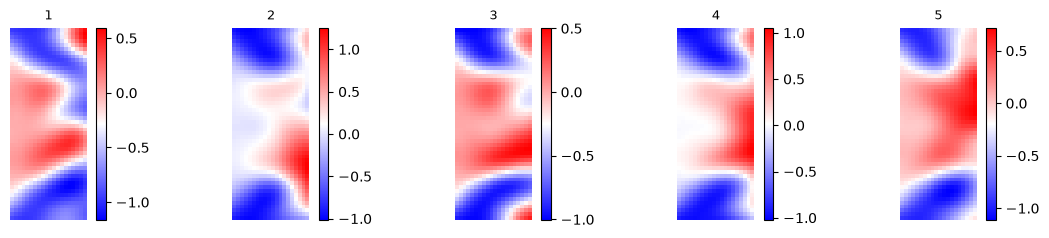

In [4]:
coords = build_grid_in_box(H, W, device)  # (H*W, 2)

kernel = gpytorch.kernels.ScaleKernel(gpytorch.kernels.RBFKernel(ard_num_dims=2)).to(device)
kernel.base_kernel.lengthscale = torch.tensor([0.05, 0.1], device=device)  # initial (space, time)
kernel.outputscale = 1.0
kernel = fit_kernel_hyperparameters(
    X_train=X_train, y_train=y_train, kernel=kernel, noise=NOISE, device=device)
posterior_mean, posterior_kernel = gp_posterior(kernel, X_train, y_train, noise=NOISE)

flow = GaussianProcessFlow(posterior_kernel, posterior_mean, coords, output_shape=(H, W), device=device)
sampler = IntegratorSampler(flow=flow)

samples = sampler.sample(NUM_SAMPLES, guidance=None, num_steps=NUM_STEPS)
show_fields(samples, cmap="bwr")

## 4. Physics condition

The PDE is imposed as an `EqualityCondition` on the finite-difference residual $u_t - \epsilon u_{xx} + 5u^3 - 5u$, which should be zero. $u_t$ is a central difference, so the residual is evaluated at every interior time; $u_{xx}$ uses a stencil that wraps around in $x$, which imposes the periodic boundary conditions exactly with no separate boundary term. `as_grid` views the flat field as $(B, C, H, W)$, with the grid shape taken from the flow when the condition is passed to the guidance.

In [5]:
class AllenCahnCondition(EqualityCondition):
    def __init__(self, sigma=10.0, eps=1e-4):
        super().__init__(sigma=sigma)
        self.register_buffer("eps", torch.tensor(float(eps)))

    def residual(self, x):  # (B, 1, H*W) -> (B, 1, H*(W-2))
        u = self.as_grid(x)[:, 0]  # (B, H, W)
        B, H, W = u.shape
        dt = 1.0 / W
        dx = 2.0 / H  # periodic grid: x_i = -1 + i*dx, and x = 1 wraps to x = -1

        u_t = (u[:, :, 2:] - u[:, :, :-2]) / (2.0 * dt)  # central difference, interior times
        u_xx = (u.roll(-1, dims=1) - 2.0 * u + u.roll(1, dims=1)) / dx**2  # periodic in x
        u_int = u[:, :, 1:-1]
        residual = u_t - self.eps * u_xx[:, :, 1:-1] + 5.0 * (u_int.pow(3) - u_int)
        return residual.reshape(B, 1, -1)

## 5. Physics-guided sampling

The condition is enforced with Monte Carlo guidance during SDE sampling from the same GP posterior flow.

  0%|          | 0/999 [00:00<?, ?it/s]

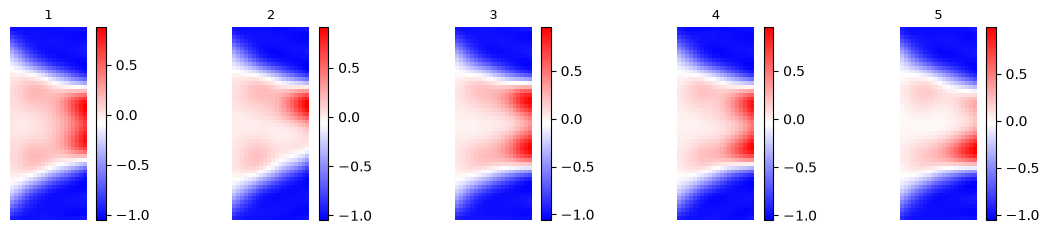

In [6]:
condition = AllenCahnCondition(sigma=1e-4).to(device)
guidance = GuidanceMC(flow, condition, num_mc_samples=1).to(device)

torch.manual_seed(SEED)
samples = sampler.sample(NUM_SAMPLES, guidance=guidance, num_steps=NUM_STEPS, sde=True)
show_fields(samples, cmap="bwr")